In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

tx = pd.read_csv("data/train_transaction.csv")
idt = pd.read_csv("data/train_identity.csv")
df = tx.merge(idt, on="TransactionID", how="left")
print(df.shape)

(590540, 434)


In [9]:
print(df["isFraud"].value_counts())
print(df["isFraud"].value_counts(normalize=True) * 100)

isFraud
0    569877
1     20663
Name: count, dtype: int64
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


            count        mean         std    min     25%   50%    75%  \
isFraud                                                                 
0        569877.0  134.511665  239.395078  0.251  43.970  68.5  120.0   
1         20663.0  149.244779  232.212163  0.292  35.044  75.0  161.0   

               max  
isFraud             
0        31937.391  
1         5191.000  


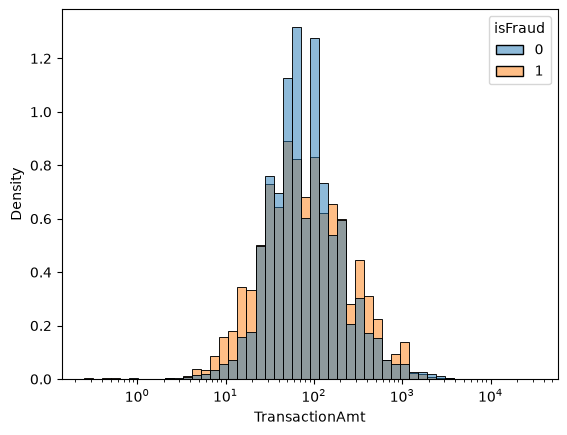

In [10]:
print(df.groupby("isFraud")["TransactionAmt"].describe())

sns.histplot(data=df, x="TransactionAmt", hue="isFraud",
             log_scale=True, bins=50, stat="density", common_norm=False)
plt.show()

C:\Users\Pranav\AppData\Local\Temp\ipykernel_5604\61393897.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["hour"] = (df["TransactionDT"] // 3600) % 24


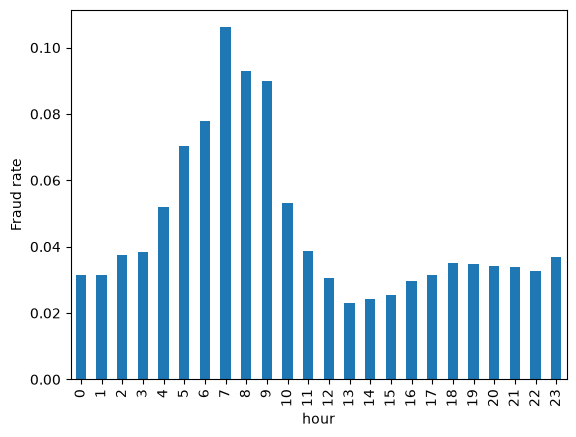

In [11]:
df["hour"] = (df["TransactionDT"] // 3600) % 24
df.groupby("hour")["isFraud"].mean().plot(kind="bar")
plt.ylabel("Fraud rate")
plt.show()

In [12]:
missing = df.isnull().mean().sort_values(ascending=False)
print(missing.head(15))

id_24    0.991962
id_25    0.991310
id_07    0.991271
id_08    0.991271
id_21    0.991264
id_26    0.991257
id_27    0.991247
id_23    0.991247
id_22    0.991247
dist2    0.936284
D7       0.934099
id_18    0.923607
D13      0.895093
D14      0.894695
D12      0.890410
dtype: float64


In [13]:
for col in ["ProductCD", "card4", "card6", "DeviceType"]:
    print(df.groupby(col)["isFraud"].agg(["mean", "count"]).sort_values("mean", ascending=False))
    print()

               mean   count
ProductCD                  
C          0.116873   68519
S          0.058996   11628
H          0.047662   33024
R          0.037826   37699
W          0.020399  439670

                      mean   count
card4                             
discover          0.077282    6651
visa              0.034756  384767
mastercard        0.034331  189217
american express  0.028698    8328

                     mean   count
card6                            
credit           0.066785  148986
debit            0.024263  439938
charge card      0.000000      15
debit or credit  0.000000      30

                mean  count
DeviceType                 
mobile      0.101662  55645
desktop     0.065215  85165

